# Week 4 - Linear Regression

In [6]:
# Load packages
import os
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.formula.api as smf

In [8]:
# Import data
obs = pd.read_csv('data/55_Hare_Data_2012.txt')
obs.head()

,date,time,grid,trap,l_ear,r_ear,sex,age,weight,hindft,notes,b_key,session_id,study
0,11/26/1998,NaN,bonrip,1A,414D096A08,NaN,NaN,NaN,1370.0,160.0,NaN,917.0,51,Population
1,11/26/1998,NaN,bonrip,2C,414D320671,NaN,M,NaN,1430.0,NaN,NaN,936.0,51,Population
2,11/26/1998,NaN,bonrip,2D,414D103E3A,NaN,M,NaN,1430.0,NaN,NaN,921.0,51,Population
3,11/26/1998,NaN,bonrip,2E,414D262D43,NaN,NaN,NaN,1490.0,135.0,NaN,931.0,51,Population
4,11/26/1998,NaN,bonrip,3B,414D2B4B58,NaN,NaN,NaN,1710.0,150.0,NaN,933.0,51,Population


In [9]:
obs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3380 entries, 0 to 3379
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        3380 non-null   object 
 1   time        264 non-null    object 
 2   grid        3380 non-null   object 
 3   trap        3368 non-null   object 
 4   l_ear       3332 non-null   object 
 5   r_ear       3211 non-null   object 
 6   sex         3028 non-null   object 
 7   age         1269 non-null   object 
 8   weight      2845 non-null   float64
 9   hindft      1633 non-null   float64
 10  notes       243 non-null    object 
 11  b_key       3333 non-null   float64
 12  session_id  3380 non-null   int64  
 13  study       3217 non-null   object 
dtypes: float64(3), int64(1), object(10)
memory usage: 369.8+ KB


In [12]:
# Transform date to datetime type
obs['date'] = pd.to_datetime(obs['date'])

print(obs['date'].dtype)

datetime64[ns]


## Examine the hares' age data

In [13]:
obs['age'].value_counts(dropna = False) # want to see NA's in the table

age
NaN          2111
A             564
J             267
a             183
j             128
1/2/2013       21
1/4/2013       21
3/4/2013       18
1              12
U              11
?              10
a 3/4 yr.       4
2 yrs.          3
u               3
A 3/4           2
1.5             2
3.5 yrs.        2
2.25 yrs        2
1 yr.           2
1 yr            2
a 1 yr.         2
A 1.5           1
2.5 yrs         1
3 yrs.          1
a 2 yrs.        1
J 3/4           1
2 yrs           1
A 1/2           1
a 1 yr          1
1.25            1
3.25 yrs.       1
Name: count, dtype: int64

When making a decicion, document it. 

We will keep all hares with a 'j' as juvenile, and all hares with 'a' as adult.

In [ ]:
# Update age values to juvenile for observations where j is included
obs.loc[obs['age'].str.contains('j', case=False, na=False), 'age'] = 'juvenile' 
# ignore case and replace rows in the age column that meet the condition with 'juvenile'
# when NA, fill with False

In [16]:
# For adults
obs.loc[obs['age'].str.contains('a', case=False, na=False), 'age'] = 'adult' 

In [19]:
# Filter for confirmed observations of juvenile and adult hares
obs_juv_adult = obs[obs['age'].isin(['juvenile', 'adult'])].copy() 
# select values from the age column that are equal to juvenile or adult

print('Number of juvenile and adult hare observations (captures):', len(obs_juv_adult))

Number of juvenile and adult hare observations (captures): 1155


In [22]:
# Extract year in which each observation happened
obs_juv_adult['year'] = obs_juv_adult['date'].dt.year

obs_juv_adult.head()

,date,time,grid,trap,l_ear,r_ear,sex,age,weight,hindft,notes,b_key,session_id,study,year
108,1999-06-23,NaN,bonrip,2C,68,69,M,juvenile,395.0,126.0,NaN,643.0,53,Population,1999
109,1999-06-23,NaN,bonrip,2E,70,71,F,juvenile,420.0,137.0,NaN,653.0,53,Population,1999
110,1999-06-23,NaN,bonrip,3D,72,73,M,juvenile,445.0,144.0,NaN,944.0,53,Population,1999
111,1999-06-23,NaN,bonrip,4B,76,77,M,juvenile,410.0,115.0,NaN,663.0,53,Population,1999
112,1999-06-23,NaN,bonrip,4C,78,79,M,juvenile,430.0,132.0,NaN,670.0,53,Population,1999


In [26]:
# Count observations per year and age, then move age values into columns
obs_per_year = obs_juv_adult.groupby(['year', 'age']).size().unstack() 
# count total observations and split index into own columns (juvenile and adult)
obs_per_year

age,adult,juvenile
year,,
1999,150.0,126.0
2000,159.0,67.0
2001,72.0,22.0
2002,3.0,NaN
2003,1.0,18.0
2004,NaN,8.0
2005,95.0,48.0
2006,101.0,15.0
2007,13.0,5.0


In [ ]:
# Check index of dataframe
obs_per_year.index

Index([1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010,
       2011, 2012],
      dtype='int32', name='year')

<Axes: title={'center': 'Juvenile and Adult Snowshoe Hare Captures per Year'}, xlabel='Year', ylabel='Number of Captures'>

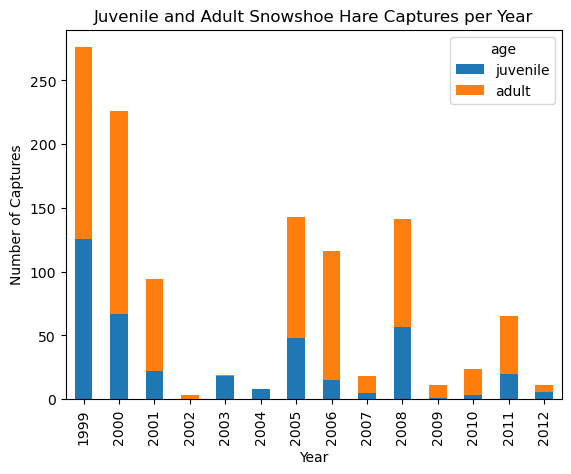

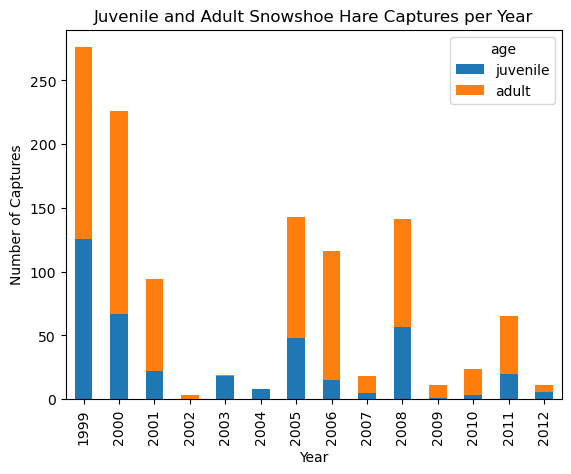

In [29]:
obs_per_year[['juvenile', 'adult']].plot(kind = 'bar',
                                         stacked = True, 
                                         title = 'Juvenile and Adult Snowshoe Hare Captures per Year',
                                         xlabel = 'Year',
                                         ylabel = 'Number of Captures')

## Plotting with matplotlib

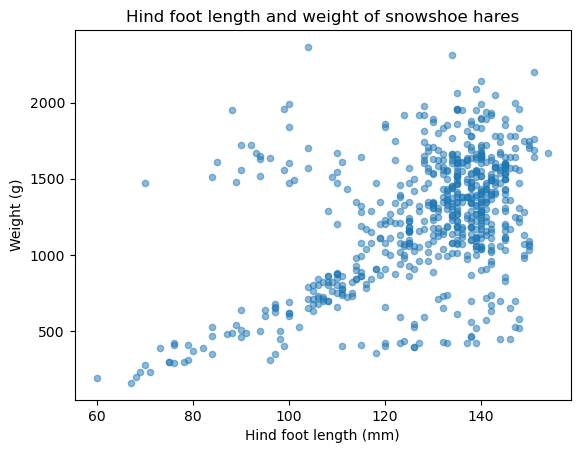

In [33]:
# Initialize empty figure (fig) and axes (ax)
fig, ax = plt.subplots()

# Add scatterplot of hares data to our figure's axes
obs_juv_adult.plot(kind = 'scatter',
                    x = 'hindft',
                    y = 'weight',
                    ax = ax, # specifies what axis we want this plot to be on
                    alpha = 0.5) 

# Update axes
ax.set_title('Hind foot length and weight of snowshoe hares')
ax.set_xlabel('Hind foot length (mm)')
ax.set_ylabel('Weight (g)')

# Display the figure
plt.show()

## Linear regression

For our analysis we want to investigate a possible relationship between hind foot length and weight for juvenile hares.

In [34]:
# subset
juvenile_w_hft = (obs_juv_adult[obs_juv_adult['age'] == 'juvenile']
.dropna(subset=['hindft','weight']))

Number of observations is: 265


<Axes: xlabel='hindft', ylabel='weight'>

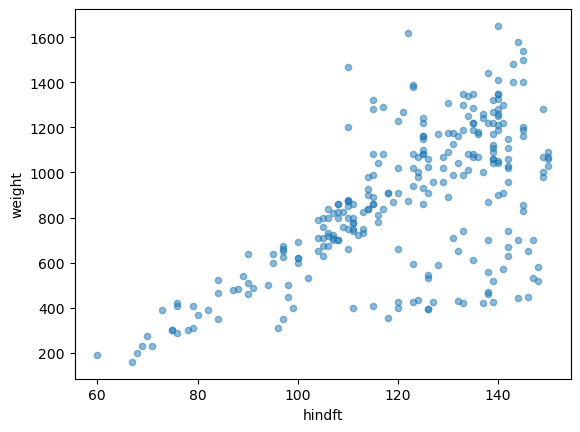

In [35]:
print('Number of observations is:', len(juvenile_w_hft))
juvenile_w_hft.plot.scatter(x= 'hindft', y = 'weight', alpha = 0.5)

In [ ]:
# Fit a model: weight explained by hind foot length
model = smf.ols('weight ~ hindft', data = juvenile_w_hft).fit() # fit() fits the model to the data

In [38]:
model.params

Intercept   -352.771986
hindft        10.092240
dtype: float64

In [39]:
# Retrieve parameters
intercept = model.params['Intercept']
print('y intercept:', intercept)

slope = model.params['hindft']
print('slope is:', slope)

y intercept: -352.771985646406
slope is: 10.09223963862301


In [40]:
print('R^2:', model.rsquared)

R^2: 0.3871164783665735


R^2 is the coefficient of determination. It is between 0 and 1. R^2 = 1 is a perfect fit of the model to the data. We interpret is as the proportion of variance in the response that is explained by the least squares line with the predictor variable. 

This model explains about 39% of the variance within the data. Not a great fit.

In [44]:
# Smallest and largest hind foot lengths
x_start = juvenile_w_hft['hindft'].min()
x_end = juvenile_w_hft['hindft'].max()

In [45]:
print(x_start, x_end)

60.0 150.0


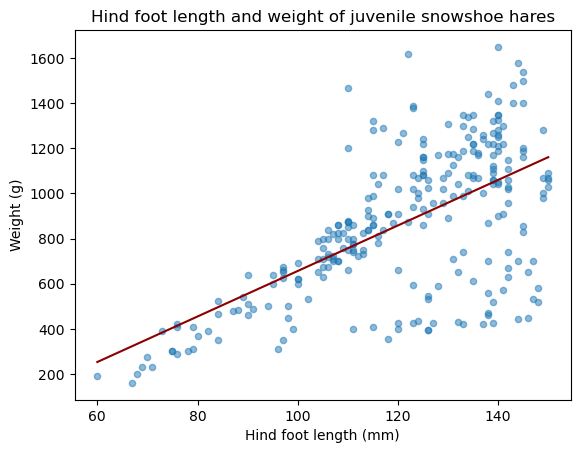

In [ ]:
# Initialize empty figure (fig) and axes (ax)
fig, ax = plt.subplots()

# Add scatterplot of data to our figure's axes
juvenile_w_hft.plot(kind = 'scatter',
                    x = 'hindft',
                    y = 'weight',
                    ax = ax, # specifies what axis we want this plot to be on
                    alpha = 0.5) 

# Add regression line to axes
ax.plot([x_start, x_end],
        [intercept + slope * x_start, intercept + slope * x_end], # construct two points and draw line between them
        color = 'darkred')

# Update axes
ax.set_title('Hind foot length and weight of juvenile snowshoe hares')
ax.set_xlabel('Hind foot length (mm)')
ax.set_ylabel('Weight (g)')

# Display the figure
plt.show()